# Forecast-then-Optimize Inventory: Does Better Demand Forecasting Reduce Stock?

**Question.** If a retailer replaces a simple forecast with a gradient-boosted model, how much less inventory does it need to hold to deliver the same service level?

**Approach.**
1. Forecast daily demand for 500 store-item series with strictly leakage-safe features (nothing newer than 28 days before the forecast date).
2. Select models on a **validation** period; evaluate on a **test** period that is used once, at the end.
3. Feed each forecast into the same base-stock (order-up-to) policy and simulate lost-sales inventory in the test period.
4. Compare methods on the **inventory-versus-fill-rate frontier**, so forecasts are judged on their operational value, not only on error metrics.

All parameters that drive the simulation (lead time, costs) are explicit assumptions in the configuration cell.

## 1. Setup

In [3]:
import json, os, subprocess, sys, time
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm

# ---- Locate the project root (works from the repo root or from notebooks/) ----------
# In Google Colab the notebook may be opened on its own, without the src/ folder.
# In that case, clone the project first. (Edit REPO_URL if your repo is named differently.)
REPO_URL = "https://github.com/oelwakil/inventory-forecast-optimization.git"
def _find_root():
    for p in (Path.cwd(), Path.cwd().parent):
        if (p / "src" / "features.py").exists():
            return p
    return None

ROOT = _find_root()
if ROOT is None and "google.colab" in sys.modules:
    subprocess.run(["git", "clone", REPO_URL], check=True)
    os.chdir(Path(REPO_URL.split("/")[-1].removesuffix(".git")) / "notebooks")
    ROOT = _find_root()
if ROOT is None:
    raise RuntimeError("Could not find the project's src/ folder. Run this notebook from the repository "
                       "(root or notebooks/ folder), or clone the repo first.")
sys.path.insert(0, str(ROOT))
from src.demo_data import make_demo_data
from src.features import FEATURES, CATEGORICAL, MIN_LAG, baseline_forecasts, build_features, to_wide
from src.metrics import summarize
from src.simulate import simulate_base_stock

# ---- Configuration --------------------------------------------------------
USE_DEMO = os.environ.get("USE_DEMO", "0") == "1"   # simulated data, smoke test only
DATA_PATH = ROOT / "data" / "train.csv"

TRAIN_END = "2016-06-30"
VAL_END = "2016-12-31"
TEST_START, TEST_END = "2017-01-01", "2017-03-31"

LEAD_TIME = 2          # days from order to arrival
REVIEW_PERIOD = 1      # review (order) every day
HOLDING_COST = 1.0     # per unit per day (relative scale)
LOST_SALE_COST = 20.0  # per unit of unmet demand (relative scale)
N_SEARCH = int(os.environ.get("N_SEARCH", 6))   # random-search trials for LightGBM (each takes a few minutes on a laptop)
SEED = 42

OUT_DIR = ROOT / "results" / ("demo" if USE_DEMO else "")
OUT_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
BLUE, ORANGE, AQUA, GRAY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#8a8985", "#0b0b0b"

## 2. Data

The notebook uses the Kaggle **Store Item Demand Forecasting Challenge** training file: daily unit sales for 50 items in 10 stores, 2013-01-01 to 2017-12-31 (`date, store, item, sales`). Download it from Kaggle (free account required), accept the competition's terms, and save it as `data/train.csv`. The file is not redistributed here.

Setting the environment variable `USE_DEMO=1` runs the whole pipeline on **simulated** data with the same schema. That is for checking the code only. Results are written to a separate folder and are not meaningful.

In [4]:
if USE_DEMO:
    print("*** USING SIMULATED DEMO DATA: results are not real ***")
    raw = make_demo_data()
elif DATA_PATH.exists():
    raw = pd.read_csv(DATA_PATH, parse_dates=["date"])
else:
    raise FileNotFoundError(
        f"{DATA_PATH} not found. Download train.csv from the Kaggle 'Store Item Demand Forecasting "
        "Challenge' and place it there (in Colab: Files panel > upload into that data/ folder). "
        "Set USE_DEMO=1 for a smoke test on simulated data only."
    )

wide = to_wide(raw)
print(f"{wide.shape[1]} series, {wide.shape[0]} days: {wide.index.min().date()} -> {wide.index.max().date()}")
print(f"mean daily sales per series: {wide.to_numpy().mean():.1f}; share of zero-sales days: {(wide.to_numpy() == 0).mean():.2%}")

500 series, 1826 days: 2013-01-01 -> 2017-12-31
mean daily sales per series: 52.3; share of zero-sales days: 0.00%


## 3. Validation design (no peeking)

| Period | Dates | Used for |
|---|---|---|
| Train | start to 2016-06-30 | fitting models |
| Validation | 2016-07-01 to 2016-12-31 | choosing hyperparameters, estimating forecast-error spread for safety stock |
| Test | 2017-01-01 to 2017-03-31 | final accuracy and inventory simulation, evaluated once |

**Leakage control.** Every feature for date *t* uses sales from *t − 28* or earlier (lags, rolling means, rolling std). One model therefore produces valid forecasts up to 28 days ahead, and unit tests in `tests/` check that changing data newer than the 28-day cut-off leaves the features unchanged.

In [5]:
feat = build_features(wide)
dates = pd.DatetimeIndex(feat["date"])
n_series = wide.shape[1]

def rows(start, end):
    return ((dates >= start) & (dates <= end)).nonzero()[0]

# rows with a complete 91-day history only, for training
usable = feat["roll_mean_91"].notna().to_numpy()
tr_idx = np.intersect1d(rows(wide.index.min(), TRAIN_END), usable.nonzero()[0])
va_idx = rows(pd.Timestamp(TRAIN_END) + pd.Timedelta(days=1), VAL_END)
trva_idx = np.intersect1d(rows(wide.index.min(), VAL_END), usable.nonzero()[0])

protection = LEAD_TIME + REVIEW_PERIOD - 1
te_end_buffered = pd.Timestamp(TEST_END) + pd.Timedelta(days=protection)
te_idx = rows(TEST_START, TEST_END)
te_buf_idx = rows(TEST_START, te_end_buffered)   # forecasts needed to size the last orders

for name, idx in [("train", tr_idx), ("validation", va_idx), ("test", te_idx)]:
    print(f"{name:<11} {len(idx):>8,} rows")

def as_matrix(values, idx):
    return np.asarray(values).reshape(-1, n_series) if len(idx) else None

y_va = feat["y"].to_numpy()[va_idx].reshape(-1, n_series)
y_te = feat["y"].to_numpy()[te_idx].reshape(-1, n_series)

train        579,500 rows
validation    92,000 rows
test          45,000 rows


## 4. Benchmarks and model selection on the validation period

In [6]:
baselines = baseline_forecasts(wide)

def window(df, start, end):
    return df.loc[start:end].to_numpy()

val_start = pd.Timestamp(TRAIN_END) + pd.Timedelta(days=1)
val_results = {}
for name, df_b in baselines.items():
    val_results[name] = summarize(y_va, window(df_b, val_start, VAL_END))
pd.DataFrame(val_results).T.round(4)

,WAPE,MAE,RMSE,Bias
Seasonal naive (t-28),0.1835,10.8392,14.2978,0.0664
Weekday average (4 wks),0.1644,9.7114,12.7260,0.0748


In [7]:
rng = np.random.default_rng(SEED)
X, y = feat[FEATURES], feat["y"]

def fit_lgb(params, train_idx, valid_idx=None, rounds=1000):
    train_set = lgb.Dataset(X.iloc[train_idx], y.iloc[train_idx], categorical_feature=CATEGORICAL, free_raw_data=False)
    kwargs = {}
    if valid_idx is not None:
        valid_set = lgb.Dataset(X.iloc[valid_idx], y.iloc[valid_idx], reference=train_set)
        kwargs = dict(valid_sets=[valid_set], callbacks=[lgb.early_stopping(40, verbose=False)])
    return lgb.train(params, train_set, num_boost_round=rounds, **kwargs)

base_params = dict(objective="poisson", learning_rate=0.1, bagging_freq=1, verbose=-1, seed=SEED, num_threads=0)
search_rows = []
t0 = time.time()
for trial in range(N_SEARCH):
    params = dict(base_params,
                  num_leaves=int(rng.choice([31, 63, 127])),
                  min_data_in_leaf=int(rng.choice([50, 100, 200])),
                  feature_fraction=float(rng.choice([0.7, 0.8, 0.9])),
                  bagging_fraction=float(rng.choice([0.7, 0.8, 0.9])),
                  lambda_l2=float(rng.choice([0.0, 1.0, 10.0])))
    model = fit_lgb(params, tr_idx, va_idx)
    pred = np.clip(model.predict(X.iloc[va_idx], num_iteration=model.best_iteration), 0, None).reshape(-1, n_series)
    m = summarize(y_va, pred)
    search_rows.append({**{k: params[k] for k in ("num_leaves", "min_data_in_leaf", "feature_fraction", "bagging_fraction", "lambda_l2")},
                        "best_iter": model.best_iteration, "val_WAPE": m["WAPE"], "val_RMSE": m["RMSE"]})
search = pd.DataFrame(search_rows).sort_values("val_WAPE").reset_index(drop=True)
print(f"search took {time.time() - t0:.0f}s")
search.round(4)

search took 88s


,num_leaves,min_data_in_leaf,feature_fraction,bagging_fraction,lambda_l2,best_iter,val_WAPE,val_RMSE
0,127,100,0.7,0.9,1.0,518,0.1035,7.9723
1,63,100,0.7,0.9,10.0,819,0.1035,7.9862
2,31,200,0.8,0.8,1.0,957,0.1036,7.9936
3,63,100,0.9,0.8,1.0,806,0.1036,7.9948
4,63,200,0.9,0.9,10.0,717,0.1036,7.9949
5,127,50,0.9,0.7,0.0,512,0.1037,7.9894


In [8]:
best = search.iloc[0]
best_params = dict(base_params, num_leaves=int(best.num_leaves), min_data_in_leaf=int(best.min_data_in_leaf),
                   feature_fraction=float(best.feature_fraction), bagging_fraction=float(best.bagging_fraction),
                   lambda_l2=float(best.lambda_l2))
best_rounds = int(best.best_iter)

# Train-only model: its validation residuals are honest out-of-sample errors used to size safety stock.
model_tr = fit_lgb(best_params, tr_idx, va_idx)
pred_va = np.clip(model_tr.predict(X.iloc[va_idx], num_iteration=best_rounds), 0, None).reshape(-1, n_series)
val_results["LightGBM"] = summarize(y_va, pred_va)
val_table = pd.DataFrame(val_results).T.round(4)
val_table

,WAPE,MAE,RMSE,Bias
Seasonal naive (t-28),0.1835,10.8392,14.2978,0.0664
Weekday average (4 wks),0.1644,9.7114,12.7260,0.0748
LightGBM,0.1035,6.1150,7.9723,-0.0120


## 5. Final model and test-period accuracy (used once)

The chosen configuration is refit on train + validation (with ~10% more boosting rounds to reflect the larger sample), then applied to the test period.

In [9]:
final_rounds = int(round(best_rounds * 1.1))
model_final = fit_lgb(best_params, trva_idx, None, rounds=final_rounds)
pred_te_buf = np.clip(model_final.predict(X.iloc[te_buf_idx]), 0, None).reshape(-1, n_series)
pred_te = pred_te_buf[: len(te_idx) // n_series]

test_start_ts = pd.Timestamp(TEST_START)
forecasts_te_buf = {"LightGBM": pred_te_buf}
for name, df_b in baselines.items():
    forecasts_te_buf[name] = window(df_b, test_start_ts, te_end_buffered)

test_results = {name: summarize(y_te, f[: y_te.shape[0]]) for name, f in forecasts_te_buf.items()}
test_table = pd.DataFrame(test_results).T.round(4)
test_table

,WAPE,MAE,RMSE,Bias
LightGBM,0.1163,5.3290,6.9073,0.0075
Seasonal naive (t-28),0.1875,8.5873,11.2833,-0.0716
Weekday average (4 wks),0.1928,8.8314,11.6463,-0.0473


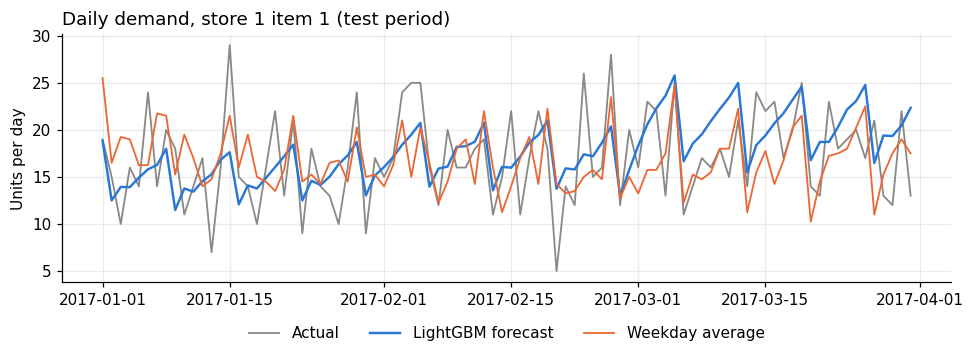

In [10]:
# Forecast vs actual for one series over the test window
s = 0
fig, ax = plt.subplots(figsize=(9, 3.4))
d_test = wide.loc[TEST_START:TEST_END].index
ax.plot(d_test, y_te[:, s], color=GRAY, lw=1.2, label="Actual")
ax.plot(d_test, pred_te[:, s], color=BLUE, lw=1.6, label="LightGBM forecast")
ax.plot(d_test, forecasts_te_buf["Weekday average (4 wks)"][: len(d_test), s], color=ORANGE, lw=1.2, label="Weekday average")
ax.set_title(f"Daily demand, store {wide.columns[s][0]} item {wide.columns[s][1]} (test period)", loc="left")
ax.set_ylabel("Units per day"); ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout(); fig.savefig(OUT_DIR / "forecast_example.png", bbox_inches="tight"); plt.show()

## 6. From forecasts to inventory decisions

Each forecast drives the same **order-up-to policy**: every day, order enough to bring *on-hand + on-order* stock up to the forecast demand over the protection period (lead time + review period − 1 days) plus safety stock

`safety stock = z × σ × √(protection period)`

where σ is each series' forecast-error RMSE **measured on the validation period only**. Sweeping the safety factor *z* traces how much inventory each forecast needs for a given service level. Unmet demand is lost. A "perfect foresight" run, which feeds the true future demand into the same policy with no safety stock, is an unreachable floor that shows how much of the remaining inventory is due to forecast error.

Assumptions: lead time, review period, and the relative holding and lost-sale costs set in the configuration cell. They are illustrative, not estimated from a real retailer.

In [11]:
# error spread per series from validation (honest out-of-sample residuals)
va_forecasts = {"LightGBM": pred_va}
for name, df_b in baselines.items():
    va_forecasts[name] = window(df_b, val_start, VAL_END)
sigma = {name: np.sqrt(np.mean((y_va - f) ** 2, axis=0)) for name, f in va_forecasts.items()}

demand = y_te
actual_buf = wide.loc[TEST_START:te_end_buffered].to_numpy()
policies = dict(forecasts_te_buf)
policies["Perfect foresight (bound)"] = actual_buf
sigma["Perfect foresight (bound)"] = np.zeros(n_series)

z_grid = np.linspace(-0.5, 3.2, 25)
sim_rows = []
for name, f in policies.items():
    for z in z_grid:
        r = simulate_base_stock(demand, f, sigma[name], z, LEAD_TIME, REVIEW_PERIOD, HOLDING_COST, LOST_SALE_COST)
        sim_rows.append({"method": name, "z": z, "fill_rate": r["fill_rate"], "in_stock_rate": r["in_stock_rate"],
                         "avg_on_hand": r["avg_on_hand"], "total_cost": r["total_cost"]})
frontier = pd.DataFrame(sim_rows)
frontier.groupby("method")[["fill_rate", "avg_on_hand"]].agg(["min", "max"]).round(3)

fill_rate      avg_on_hand        
                                min  max         min     max
method                                                      
LightGBM                      0.919  1.0       2.988  35.899
Perfect foresight (bound)     1.000  1.0       0.350   0.350
Seasonal naive (t-28)         0.801  1.0       2.322  55.380
Weekday average (4 wks)       0.822  1.0       3.932  50.568

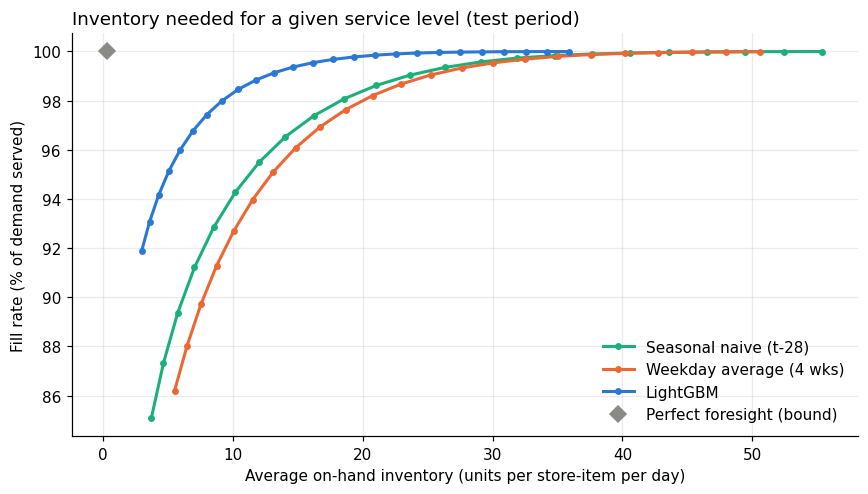

In [12]:
order = ["Seasonal naive (t-28)", "Weekday average (4 wks)", "LightGBM", "Perfect foresight (bound)"]
style = {"Seasonal naive (t-28)": (AQUA, "-"), "Weekday average (4 wks)": (ORANGE, "-"),
         "LightGBM": (BLUE, "-"), "Perfect foresight (bound)": (GRAY, "--")}
fig, ax = plt.subplots(figsize=(8, 4.6))
for name in order:
    d = frontier[frontier.method == name].sort_values("fill_rate")
    d = d[(d.fill_rate >= 0.85)]
    c, ls = style[name]
    if name.startswith("Perfect"):   # degenerate frontier: 100% fill at any z, so show its cheapest point
        p = d.sort_values("avg_on_hand").iloc[0]
        ax.plot([p.avg_on_hand], [p.fill_rate * 100], color=c, marker="D", ms=7, ls="none", label=name)
        continue
    ax.plot(d.avg_on_hand, d.fill_rate * 100, color=c, ls=ls, lw=2, marker="o", ms=3.5, label=name)
ax.set_xlabel("Average on-hand inventory (units per store-item per day)")
ax.set_ylabel("Fill rate (% of demand served)")
ax.set_title("Inventory needed for a given service level (test period)", loc="left")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig(OUT_DIR / "inventory_frontier.png", bbox_inches="tight"); plt.show()

In [13]:
# Inventory required to reach target fill rates (linear interpolation on the frontier)
targets = [0.95, 0.98, 0.99]
rows_out = []
for name in order:
    d = frontier[frontier.method == name].sort_values("fill_rate")
    line = {"method": name}
    for t in targets:
        if name.startswith("Perfect"):   # no forecast error: smallest stock that still serves >= t
            line[f"on-hand @ {t:.0%} fill"] = d.loc[d.fill_rate >= t, "avg_on_hand"].min()
        else:
            line[f"on-hand @ {t:.0%} fill"] = (np.interp(t, d.fill_rate, d.avg_on_hand)
                                                if d.fill_rate.min() <= t <= d.fill_rate.max() else np.nan)
    rows_out.append(line)
need = pd.DataFrame(rows_out).set_index("method")
ref = need.loc["Weekday average (4 wks)"]
reduction = (1 - need / ref).drop(index=["Weekday average (4 wks)", "Perfect foresight (bound)"]) * 100
print("Average on-hand inventory required (units per store-item per day)")
display(need.round(2))
print("Inventory reduction vs. the weekday-average benchmark at equal fill rate (%)")
display(reduction.round(1))

Average on-hand inventory required (units per store-item per day)


,on-hand @ 95% fill,on-hand @ 98% fill,on-hand @ 99% fill
method,,,
Seasonal naive (t-28),11.29,18.33,23.41
Weekday average (4 wks),12.98,20.02,24.96
LightGBM,4.97,9.19,12.55
Perfect foresight (bound),0.35,0.35,0.35


Inventory reduction vs. the weekday-average benchmark at equal fill rate (%)


,on-hand @ 95% fill,on-hand @ 98% fill,on-hand @ 99% fill
method,,,
Seasonal naive (t-28),13.0,8.5,6.2
LightGBM,61.7,54.1,49.7


In [14]:
# Lowest simulated total cost for each method over the z grid
best_cost = (frontier.loc[frontier.groupby("method").total_cost.idxmin()]
             .set_index("method").loc[order, ["z", "fill_rate", "avg_on_hand", "total_cost"]])
best_cost["cost_vs_weekday_avg_%"] = (best_cost.total_cost / best_cost.loc["Weekday average (4 wks)", "total_cost"] - 1) * 100
best_cost.round(3)

,z,fill_rate,avg_on_hand,total_cost,cost_vs_weekday_avg_%
method,,,,,
Seasonal naive (t-28),1.658,0.993,26.315,1452274.833,-4.473
Weekday average (4 wks),1.812,0.993,27.615,1520276.676,0.000
LightGBM,1.350,0.995,16.163,915363.174,-39.790
Perfect foresight (bound),-0.500,1.000,0.350,15772.000,-98.963


## 7. Save results

Everything reported in the README is written to `results/` so the numbers can be traced to this run.

In [15]:
summary = {
    "data_source": "SIMULATED DEMO DATA" if USE_DEMO else "Kaggle Store Item Demand Forecasting Challenge",
    "splits": {"train_end": TRAIN_END, "val_end": VAL_END, "test": [TEST_START, TEST_END]},
    "simulation": {"lead_time": LEAD_TIME, "review_period": REVIEW_PERIOD,
                   "holding_cost": HOLDING_COST, "lost_sale_cost": LOST_SALE_COST},
    "lightgbm": {**{k: (v if not isinstance(v, np.generic) else v.item()) for k, v in best_params.items()},
                 "rounds_validation": best_rounds, "rounds_final": final_rounds},
    "validation_accuracy": val_table.to_dict("index"),
    "test_accuracy": test_table.to_dict("index"),
    "inventory_required": need.round(4).to_dict("index"),
    "inventory_reduction_vs_weekday_avg_pct": reduction.round(2).to_dict("index"),
    "lowest_cost": best_cost.round(4).to_dict("index"),
}
(OUT_DIR / "summary.json").write_text(json.dumps(summary, indent=2))
frontier.to_csv(OUT_DIR / "frontier.csv", index=False)
print("saved to", OUT_DIR.resolve())

saved to /content/inventory-forecast-optimization/results


## 8. Limitations

- The data is one retailer's daily sales for 500 series with little intermittent demand. Slow-moving or intermittent items would need different forecasting methods (for example Croston-type models or quantile forecasts).
- Safety stock assumes forecast errors scale with √(protection period) and are estimated from one validation window.
- Lead time is fixed and known, orders are unconstrained (no capacity, minimum order quantities, or shelf life), and unmet demand is lost. Costs are relative, not estimated.
- One test window (three months) is evaluated once. A rolling-origin evaluation would give a sense of variability across seasons.